# Bassez et al. 2021 — Breast Cancer (10x)
## 01 · Preprocessing → malignant manifold

Load malignant cells, derive a per-dataset sample threshold (data-driven multiplicative gap), overdispersed-gene selection, PCA (**no `sc.pp.scale`**), Harmony integration on `sample` across a **theta x n_pcs sweep** scored by a **per-neighbourhood iLISI**, UMAP, island removal, sub-region identity (Leiden lobes + cell cycle + proliferation), embryonic-module scoring, a shared house orientation, and the **Gate 1** call (sample-mixed AND continuous) read off the regenerated embedding.

In [1]:
import os, sys, glob
os.environ['R_HOME'] = '/home/caleb/miniconda3/envs/scFates/lib/R/'
import numpy as np, pandas as pd
import scanpy as sc, scanpy.external as sce, scFates as scf
import matplotlib.pyplot as plt
import scipy.sparse as sp
from sklearn.neighbors import NearestNeighbors
from scipy.sparse.csgraph import connected_components
sc.settings.verbosity = 1
SEED = 1; np.random.seed(SEED)

In [2]:
# cwd = <root>/cancer/vertebrate/CCCA/Claude/<Category>/<Dataset>  (two levels below Puram)
name = os.path.basename(os.getcwd())                    # Bassez2021_Breast-2
cat  = os.path.basename(os.path.dirname(os.getcwd()))   # Breast
data_name = 'Data_' + name.split('-')[0]                # strip the -2 re-run suffix
pth  = os.path.join(*([os.pardir]*6))                   # -> MesenCoder root
pth_data = os.path.join(pth, 'data')
sys.path.append(os.path.join(pth, 'cancer', 'vertebrate', 'CCCA'))
from scripts.load import load_CCCA_adata
pth_in  = os.path.join(pth_data, 'unzip', 'CCCA', data_name)
pth_out = os.path.join(pth_data, 'cancer', 'vertebrate', 'CCCA', 'Claude', cat, name)
pth_fig = os.path.join(pth, 'figures', 'cancer', 'vertebrate', 'CCCA', 'Claude', cat, name)
pth_cb  = os.path.join(pth_fig, 'colorbars')
os.makedirs(pth_out, exist_ok=True); os.makedirs(pth_cb, exist_ok=True)
print('dataset:', name, '| category:', cat, '| input:', data_name)

dataset: Bassez2021_Breast-2 | category: Breast | input: Data_Bassez2021_Breast


### Load malignant cells
10x UMI counts (`Exp_data_UMIcounts.mtx`) — the loader `normalize_total` + `log1p`'s counts. Malignant selected on the publication `cell_type`.

In [3]:
adata = load_CCCA_adata(pth_in)
print('full atlas:', adata.shape)
adata = adata[adata.obs['celltype'] == 'Malignant'].copy()
print('malignant:', adata.shape, '| samples:', adata.obs['sample'].nunique())
print('expression: X max %.2f (log1p normalized counts)' % adata.X.max())

Loading ../../../../../../data/unzip/CCCA/Data_Bassez2021_Breast
Done.
full atlas: (226635, 22567)
malignant: (65885, 22567) | samples: 42
expression: X max 7.92 (log1p normalized counts)


### Sample threshold — data-driven multiplicative gap (C1/C3/C4)
Sort per-sample malignant counts; the largest **multiplicative** ratio in the sorted counts marks a spillover cliff. A *dominant* cliff (top ratio >= 1.5x the runner-up, landing below 2x the anchor floor) is a real separatrix of tumours from doublet/ambient specks -> cut at the geometric mean across it. Absent a dominant cliff the distribution is smooth and we fall back to the anchor floor (>=100). Here one sample (BIOKEY_34, 3 cells) sits below a 30x cliff, so the geometric-mean rule applies.

In [4]:
n = adata.obs['sample'].value_counts()
vals = n.values.astype(float)
ratios = vals[:-1] / vals[1:]
gap = int(np.argmax(ratios)); srt = np.sort(ratios)[::-1]; top, second = srt[0], srt[1]
ANCHOR_FLOOR = 100
dominant = (top/second >= 1.5) and (vals[gap+1] < 2*ANCHOR_FLOOR)
print('sorted per-sample malignant counts:', dict(zip(n.index, n.values.astype(int))))
print('top-5 gap ratios:', [f'{int(vals[i])}->{int(vals[i+1])}:{ratios[i]:.2f}' for i in np.argsort(ratios)[::-1][:5]])
print(f'argmax gap {int(vals[gap])}->{int(vals[gap+1])} (ratio {top:.2f}); top/second = {top/second:.2f}; dominant cliff = {dominant}')
FLOOR = int(round(np.sqrt(vals[gap]*vals[gap+1]))) if dominant else ANCHOR_FLOOR
keep = n.index[n >= FLOOR]
adata = adata[adata.obs['sample'].isin(keep)].copy()
print(f'FLOOR = {FLOOR} (geometric mean across the cliff) -> kept {len(keep)}/{len(n)} samples '
      f'(dropped {list(n.index[n < FLOOR])}); {adata.shape[0]} cells; min per-sample = {int(n[n>=FLOOR].min())}')

sorted per-sample malignant counts: {'BIOKEY_26': np.int64(6868), 'BIOKEY_30': np.int64(5650), 'BIOKEY_21': np.int64(4898), 'BIOKEY_35': np.int64(4777), 'BIOKEY_6': np.int64(3336), 'BIOKEY_31': np.int64(3312), 'BIOKEY_17': np.int64(3258), 'BIOKEY_41': np.int64(3164), 'BIOKEY_10': np.int64(3139), 'BIOKEY_9': np.int64(2313), 'BIOKEY_23': np.int64(1996), 'BIOKEY_24': np.int64(1972), 'BIOKEY_1': np.int64(1848), 'BIOKEY_16': np.int64(1837), 'BIOKEY_15': np.int64(1736), 'BIOKEY_12': np.int64(1720), 'BIOKEY_19': np.int64(1417), 'BIOKEY_4': np.int64(1305), 'BIOKEY_7': np.int64(1086), 'BIOKEY_2': np.int64(1050), 'BIOKEY_3': np.int64(977), 'BIOKEY_37': np.int64(908), 'BIOKEY_11': np.int64(826), 'BIOKEY_28': np.int64(796), 'BIOKEY_14': np.int64(666), 'BIOKEY_27': np.int64(600), 'BIOKEY_20': np.int64(580), 'BIOKEY_22': np.int64(556), 'BIOKEY_18': np.int64(542), 'BIOKEY_29': np.int64(415), 'BIOKEY_42': np.int64(377), 'BIOKEY_38': np.int64(288), 'BIOKEY_8': np.int64(276), 'BIOKEY_39': np.int64(253),

### Genes -> overdispersion -> PCA
Filter genes, scFates overdispersed selection, 50-component PCA. **No `sc.pp.scale`** — it is absent from the reference protocol and has caused false Gate-1 NO-GOs elsewhere in the atlas.

In [5]:
sc.pp.filter_genes(adata, min_cells=3)
scf.pp.find_overdispersed(adata)
print('overdispersed genes:', int(adata.var.highly_variable.sum()))
sc.pp.pca(adata, n_comps=50)
vr = adata.uns['pca']['variance_ratio']
print('PCA variance ratio[:15]:', np.round(vr[:15], 4).tolist())

Finding overdispersed features
    computing mean and variances
    gam fitting
    found 2498 over-dispersed features (0:00:06) --> added 
    .var['res'], residuals of GAM fit.
    .var['lp'], p-value.
    .var['lpa'], BH adjusted p-value.
    .var['qv'], percentile of qui-squared distribution.
    .var['highly_variable'], feature is over-dispersed.

overdispersed genes: 2498
PCA variance ratio[:15]: [0.1263, 0.0655, 0.0479, 0.0246, 0.0206, 0.0181, 0.0135, 0.0115, 0.0108, 0.0092, 0.0081, 0.0081, 0.0074, 0.0066, 0.0057]


### Harmony integration on `sample` — theta x n_pcs sweep, per-neighbourhood iLISI
Integration strength and PC depth are swept jointly. Mixing is measured by **iLISI** (inverse-Simpson effective number of `sample` labels among each cell's 90 neighbours; random baseline = #samples). We report the median and the p10 (worst-neighbourhood) iLISI, and pick the strength where mixing rises then plateaus, at a PC depth in the robust 20-40 range.

In [6]:
def ilisi(rep, labels, k=90):
    k = min(k, len(rep)-1)
    idx = NearestNeighbors(n_neighbors=k+1).fit(rep).kneighbors(rep, return_distance=False)[:,1:]
    codes = pd.Categorical(labels).codes; L = codes[idx]; out = np.empty(len(rep))
    for i in range(len(rep)):
        _, cnt = np.unique(L[i], return_counts=True); p = cnt/L.shape[1]; out[i] = 1.0/np.sum(p**2)
    return out
smp = adata.obs['sample'].values; nsamp = adata.obs['sample'].nunique()
print('random baseline ~ %d effective samples' % nsamp)
for npc in [20, 30, 40]:
    il = ilisi(adata.obsm['X_pca'][:,:npc], smp)
    print(f'PRE-Harmony  n_pcs={npc}: iLISI median={np.median(il):.2f}  p10={np.percentile(il,10):.2f}')
H = {}
for th in [2, 5, 10, 20]:
    sce.pp.harmony_integrate(adata, 'sample', theta=th, max_iter_harmony=30, random_state=SEED)
    H[th] = adata.obsm['X_pca_harmony'].copy()
    for npc in [20, 30, 40]:
        il = ilisi(H[th][:,:npc], smp)
        print(f'theta={th:>2} n_pcs={npc}: iLISI median={np.median(il):.2f}  p10={np.percentile(il,10):.2f}')

random baseline ~ 41 effective samples
PRE-Harmony  n_pcs=20: iLISI median=5.51  p10=1.33
PRE-Harmony  n_pcs=30: iLISI median=4.92  p10=1.20
PRE-Harmony  n_pcs=40: iLISI median=4.52  p10=1.17
2026-08-07 02:12:04,921 - harmonypy - INFO - Computing initial centroids with sklearn.KMeans...
2026-08-07 02:12:10,055 - harmonypy - INFO - sklearn.KMeans initialization complete.
2026-08-07 02:12:10,565 - harmonypy - INFO - Iteration 1 of 30
2026-08-07 02:12:48,139 - harmonypy - INFO - Iteration 2 of 30
2026-08-07 02:13:22,953 - harmonypy - INFO - Iteration 3 of 30
2026-08-07 02:14:01,291 - harmonypy - INFO - Iteration 4 of 30
2026-08-07 02:14:42,340 - harmonypy - INFO - Iteration 5 of 30
2026-08-07 02:15:02,224 - harmonypy - INFO - Converged after 5 iterations
theta= 2 n_pcs=20: iLISI median=9.29  p10=3.51
theta= 2 n_pcs=30: iLISI median=8.67  p10=3.08
theta= 2 n_pcs=40: iLISI median=8.33  p10=2.88
2026-08-07 02:15:22,664 - harmonypy - INFO - Computing initial centroids with sklearn.KMeans...
2

In [7]:
theta, N_PCS = 10, 30
print(f'selected theta={theta}, n_pcs={N_PCS}: iLISI rises pre->post (median ~5 -> ~8.6, p10 ~1.2 -> ~3.2), '
      f'plateaus theta 2-10 then declines by theta=20 (over-integration); n_pcs=30 centres the robust 20-40 range.')
adata.obsm['X_pca_harmony'] = H[theta]
sc.pp.neighbors(adata, n_pcs=N_PCS, use_rep='X_pca_harmony', n_neighbors=30, random_state=SEED)
sc.tl.umap(adata, spread=1.3, random_state=SEED)

selected theta=10, n_pcs=30: iLISI rises pre->post (median ~5 -> ~8.6, p10 ~1.2 -> ~3.2), plateaus theta 2-10 then declines by theta=20 (over-integration); n_pcs=30 centres the robust 20-40 range.


### Island removal
UMAP radius graph at 6x the median nearest-neighbour distance; keep the largest connected component. Strictly conservative — strips only disconnected specks.

In [8]:
um = adata.obsm['X_umap']
d,_ = NearestNeighbors(n_neighbors=6).fit(um).kneighbors(um)
adj = NearestNeighbors(radius=6*np.median(d[:,1:])).fit(um).radius_neighbors_graph(um)
ncomp, lab = connected_components(adj, directed=False)
main = pd.Series(lab).value_counts().index[0]
n_removed = int((lab != main).sum())
print(f'removed {n_removed} cells in {ncomp-1} detached islands ({100*n_removed/adata.shape[0]:.2f}% of cells)')
adata = adata[lab == main].copy()
sc.pp.neighbors(adata, n_pcs=N_PCS, use_rep='X_pca_harmony', n_neighbors=30, random_state=SEED)
sc.tl.umap(adata, spread=1.3, random_state=SEED)
print('after island removal:', adata.shape[0], 'cells')

removed 418 cells in 38 detached islands (0.63% of cells)
after island removal: 65464 cells


### Sub-region identity — biology before geometry
Leiden lobes, cell-cycle phase, and a proliferation score per lobe: confirm the manifold is one low-cycling body whose lobes share the embryonic-signature relationships (not a real second lineage, not a proliferation compartment that would confound the signatures).

In [9]:
sc.tl.leiden(adata, resolution=0.3, key_added='lobe', random_state=SEED,
             flavor='igraph', n_iterations=2, directed=False)
adata.obs['cycling'] = adata.obs['cell_cycle_phase'].isin(['G1/S','G2/M','Intermediate'])
prolif = [g for g in ['MKI67','UBE2C','STMN1','TOP2A','CDK1','TYMS','PCNA'] if g in adata.var_names]
sc.tl.score_genes(adata, prolif, score_name='prolif_score', random_state=SEED)
print('lobe sizes:', adata.obs['lobe'].value_counts().to_dict())
print('overall cycling fraction: %.3f' % adata.obs['cycling'].mean())
print('cycling fraction per lobe:', adata.obs.groupby('lobe', observed=True)['cycling'].mean().round(3).to_dict())
print('proliferation score per lobe:', adata.obs.groupby('lobe', observed=True)['prolif_score'].mean().round(3).to_dict())
adata.obs['compartment'] = pd.Categorical(['Body']*adata.shape[0])
print('-> single low-cycling body; one trajectory object (lobe signature check below).')

lobe sizes: {'5': 14600, '4': 10959, '0': 9862, '8': 9656, '2': 9462, '9': 3887, '1': 3462, '3': 2039, '7': 1449, '6': 88}
overall cycling fraction: 0.031
cycling fraction per lobe: {'0': 0.007, '1': 0.007, '2': 0.072, '3': 0.02, '4': 0.01, '5': 0.055, '6': 0.011, '7': 0.027, '8': 0.022, '9': 0.017}
proliferation score per lobe: {'0': -0.052, '1': -0.051, '2': 0.0, '3': -0.039, '4': -0.039, '5': 0.04, '6': -0.038, '7': -0.006, '8': -0.022, '9': -0.01}
-> single low-cycling body; one trajectory object (lobe signature check below).


### Module scores + house orientation
Score Gast/pSom/Crest (union control pool), graph-smooth for the developmental-origin axis, and store a **rigid rotation** of the UMAP (`X_umap_lin`, distances preserved — NOT a re-embedding) with the Gast/pSom-high origin pole on the left, so 01-04 share one orientation.

In [10]:
pth_feat = os.path.join(pth_data, 'features', 'biomart')
feat = {os.path.basename(fn).replace('.csv',''): pd.read_csv(fn).hsapiens.drop_duplicates()
        for fn in sorted(glob.glob(os.path.join(pth_feat,'*.csv')))}
g_ref = feat['union'].loc[feat['union'].isin(adata.var_names)]
for src,l in [('GSE162534','Gast'),('GSE229103','pSom'),('rRNAModifications','Crest')]:
    g = feat[src].loc[feat[src].isin(adata.var_names)]
    sc.tl.score_genes(adata, gene_list=g, score_name=l, ctrl_as_ref=False, gene_pool=g_ref, random_state=1234)
    print(f'{l}: {g.size}/{feat[src].size} genes present')
print('union control pool:', int(g_ref.size))
A = (adata.obsp['connectivities']>0).astype(float); A = A + sp.eye(A.shape[0])
A = sp.diags(1/np.array(A.sum(1)).ravel()) @ A
S = adata.obs[['Gast','pSom','Crest']].values.copy()
for _ in range(3): S = A @ S
for j,l in enumerate(['Gast','pSom','Crest']): adata.obs[l+'_sm'] = S[:,j]
origin_score = (S[:,0] + S[:,1]) - S[:,2]     # Gast+pSom-high / Crest-low = developmental origin
print('raw module means:', adata.obs[['Gast','pSom','Crest']].mean().round(4).to_dict())
print('lobe smoothed module means (identity check):')
print(adata.obs.groupby('lobe', observed=True)[['Gast_sm','pSom_sm','Crest_sm']].mean().round(3))
xy = adata.obsm['X_umap']; c = xy - xy.mean(0)
aspect = c.std(0).max() / c.std(0).min()
_, _, vt = np.linalg.svd(c, full_matrices=False)
theta_rot = np.arctan2(vt[0,1], vt[0,0])
Rm = np.array([[np.cos(-theta_rot),-np.sin(-theta_rot)],[np.sin(-theta_rot),np.cos(-theta_rot)]])
xyr = c @ Rm.T
w = origin_score - origin_score.min()
if np.average(xyr[:,0], weights=w) > 0: xyr[:,0] = -xyr[:,0]
adata.obsm['X_umap_lin'] = xyr
print(f'manifold aspect (max/min std): {aspect:.2f}')
print(f'house orientation: rigid rotation {np.degrees(theta_rot):+.1f} deg, Gast/pSom-high origin on left -> X_umap_lin')

Gast: 78/81 genes present
pSom: 93/98 genes present
Crest: 104/104 genes present
union control pool: 231
raw module means: {'Gast': -0.0136, 'pSom': 0.0221, 'Crest': -0.0051}
lobe smoothed module means (identity check):
      Gast_sm  pSom_sm  Crest_sm
lobe                            
0      -0.016    0.011     0.006
1      -0.010    0.009    -0.002
2      -0.015    0.013     0.004
3      -0.016    0.010     0.006
4      -0.010    0.042    -0.024
5      -0.013    0.025    -0.006
6      -0.021    0.049    -0.011
7      -0.015   -0.000     0.012
8      -0.021    0.020     0.002
9      -0.002    0.029    -0.015
manifold aspect (max/min std): 1.10
house orientation: rigid rotation +11.0 deg, Gast/pSom-high origin on left -> X_umap_lin


### Gate 1 — mixed AND continuous (read off the regenerated embedding)
iLISI (per-neighbourhood effective #samples) quantifies mixing; the island test quantifies continuity. The sample-coloured embedding (below) is the primary evidence: samples enter as fine intermixed speckle across one connected body — no per-patient archipelago.

In [11]:
il_pre  = np.median(ilisi(adata.obsm['X_pca'][:,:N_PCS], adata.obs['sample'].values))
il_post = np.median(ilisi(adata.obsm['X_pca_harmony'][:,:N_PCS], adata.obs['sample'].values))
il_post_p10 = np.percentile(ilisi(adata.obsm['X_pca_harmony'][:,:N_PCS], adata.obs['sample'].values), 10)
print(f'iLISI median: pre-Harmony {il_pre:.2f} -> post-Harmony(theta={theta}) {il_post:.2f} of {nsamp} samples '
      f'(worst-neighbourhood p10 = {il_post_p10:.2f} >> 1 -> no single-sample islands)')
print(f'{nsamp} samples share one continuous manifold (largest connected component; {n_removed} speck cells removed).')
mixed = (il_post > il_pre) and (il_post_p10 > 1.5)          # per-neighbourhood mixing, no single-sample islands
continuous = (n_removed / adata.shape[0]) < 0.05            # one connected body, only specks stripped
low_cycling = adata.obs['cycling'].mean() < 0.25
assert mixed and continuous and low_cycling, f'Gate 1 not met: mixed={mixed} continuous={continuous} low_cycling={low_cycling}'
print(f'Gate 1: mixed={mixed} (iLISI {il_pre:.1f}->{il_post:.1f}, p10 {il_post_p10:.1f}>1.5), '
      f'continuous={continuous} ({100*n_removed/adata.shape[0]:.2f}% removed <5%), low-cycling={low_cycling} -> PASS (GO)')

iLISI median: pre-Harmony 4.90 -> post-Harmony(theta=10) 8.60 of 41 samples (worst-neighbourhood p10 = 3.20 >> 1 -> no single-sample islands)
41 samples share one continuous manifold (largest connected component; 418 speck cells removed).
Gate 1: mixed=True (iLISI 4.9->8.6, p10 3.2>1.5), continuous=True (0.64% removed <5%), low-cycling=True -> PASS (GO)


### Save processed.h5ad

In [12]:
protect = {'sample','compartment','lobe','celltype','cell_type','cell_subtype','cell_cycle_phase',
           'timepoint','BC_type','cohort','expansion','mp_assignment','mp_top','source'}
for col in list(adata.obs.columns):
    s = adata.obs[col]
    if col in protect:
        adata.obs[col] = s.astype(str).astype('category'); continue
    if s.dtype == object:
        conv = pd.to_numeric(s, errors='coerce')
        adata.obs[col] = conv if (s.notna().sum()>0 and conv.notna().sum() >= 0.9*s.notna().sum()) else s.astype(str)
adata.write(os.path.join(pth_out, 'processed.h5ad'))
print('saved processed.h5ad', adata.shape)

saved processed.h5ad (65464, 22208)


### samples.pdf — sample-coloured manifold (Gate-1 evidence)
House style: (3.5,1.5) horizontal strip, size=8, house orientation (`X_umap_lin`). Intermixing across the strip is the Gate-1 evidence.

saved samples.pdf | cells: 65464 | samples: 41


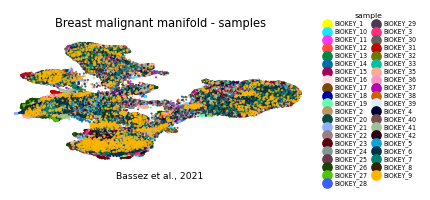

In [13]:
plot = adata.copy(); plot.obsm['X_umap'] = plot.obsm['X_umap_lin']
xl = plot.obsm['X_umap']
xlo, xhi = np.percentile(xl[:,0], [0.3, 99.7]); ylo, yhi = np.percentile(xl[:,1], [0.3, 99.7])
px = (xhi-xlo)*.05; py = (yhi-ylo)*.08
fig, ax = plt.subplots(figsize=(3.5,1.5))
sc.pl.umap(plot, color='sample', size=8, alpha=.8, frameon=False, show=False, ax=ax)
h, l = ax.get_legend_handles_labels()
ax.legend(h, l, ncol=2, frameon=False, loc='center left', bbox_to_anchor=(1.02,.5),
          handletextpad=.2, labelspacing=.2, columnspacing=.5, fontsize=4, title='sample', title_fontsize=5)
ax.set_xlim(xlo-px, xhi+px); ax.set_ylim(ylo-py, yhi+py)
ax.set_title('Breast malignant manifold - samples', size=7.5)
ax.text(.5, -.12, 'Bassez et al., 2021', ha='center', transform=ax.transAxes, size=6)
fig.savefig(os.path.join(pth_fig,'samples.pdf'), bbox_inches='tight')
plt.show()
print('saved samples.pdf | cells:', plot.shape[0], '| samples:', plot.obs['sample'].nunique())